<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Hypothesis testing in action - Solution

---

### About
An introduction to hypothesis testing in action.

### Learning Objectives
- Define the key steps and terms in hypothesis testing.

### Notebook Guide
- Scenario
- Exploring the results
- Now You Try
- Conclusions and Takeaways

# Scenario

You’re an analyst for BIG Sodas, a producer of soft drinks.

They want to bring out a sugar-free version of their most popular lemonade drink, BIG Lemon.

They have two formulas they want to test: BIG Lemon Zero and Diet BIG Lemon.

They want you to help design an experiment to decide which of the two versions to produce.

The basic idea of the experiment is to do blind taste tests to see which flavour people prefer.

# Exploring the results

Let's open and explore the results of one of our blind taste tests.

In [1]:
import pandas as pd

In [2]:
soda_results = pd.read_csv("https://raw.githubusercontent.com/CharleyHananiaGA/DSB-Unit-02/refs/heads/main/data/sodas.csv")
soda_rows = soda_results.shape[0]
soda_columns = soda_results.shape[1]
print(f"Number of rows in soda_results:    {soda_rows}")
print(f"Number of columns in soda_results: {soda_columns}")
soda_results.head()

Number of rows in soda_results:    400
Number of columns in soda_results: 2


,soda,rating
0,diet_big_lemon,5
1,big_lemon_zero,8
2,big_lemon_zero,7
3,diet_big_lemon,5
4,big_lemon_zero,6


We have a data set of the two types of soda and the associated taste test rating.

Let's see the distribution of both the sodas and the ratings.

In [3]:
soda_results["soda"].value_counts()

soda
diet_big_lemon    200
big_lemon_zero    200
Name: count, dtype: int64

In [4]:
soda_results.groupby("soda")["rating"].value_counts().sort_index()

soda            rating
big_lemon_zero  5          1
                6         30
                7         65
                8         77
                9         23
                10         4
diet_big_lemon  3          5
                4         29
                5         73
                6         64
                7         25
                8          3
                9          1
Name: count, dtype: int64

In [5]:
soda_results.groupby("soda").describe() #this will give you the count, mean, std, min, 25%, 50%, 75%, and max for each soda group

rating                                           
                count   mean       std  min  25%  50%  75%   max
soda                                                            
big_lemon_zero  200.0  7.515  0.966668  5.0  7.0  8.0  8.0  10.0
diet_big_lemon  200.0  5.440  1.044921  3.0  5.0  5.0  6.0   9.0

In [6]:
soda_results.groupby("rating").describe() #this will give you the count, mean, std, min, 25%, 50%, 75%, and max for each rating group

soda                            
       count unique             top freq
rating                                  
3          5      1  diet_big_lemon    5
4         29      1  diet_big_lemon   29
5         74      2  diet_big_lemon   73
6         94      2  diet_big_lemon   64
7         90      2  big_lemon_zero   65
8         80      2  big_lemon_zero   77
9         24      2  big_lemon_zero   23
10         4      1  big_lemon_zero    4

In [7]:
soda_results.describe()

,rating
count,400.000000
mean,6.477500
std,1.445586
min,3.000000
25%,5.000000
50%,6.000000
75%,8.000000
max,10.000000


In [8]:
soda_results["rating"].value_counts().sort_index()

rating
3      5
4     29
5     74
6     94
7     90
8     80
9     24
10     4
Name: count, dtype: int64

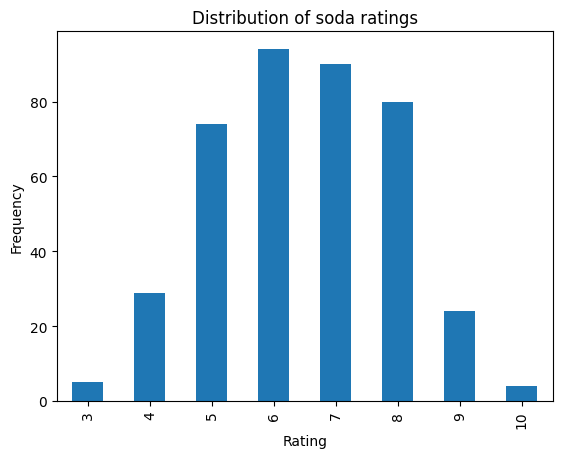

In [9]:
(
    soda_results["rating"]
    .value_counts()
    .sort_index()
    .plot(
        kind="bar",
        title="Distribution of soda ratings",
        xlabel="Rating",
        ylabel="Frequency",
    )
);

What we're really interested in is the distribution of ratings *for each soda*.

In [10]:
import seaborn as sb

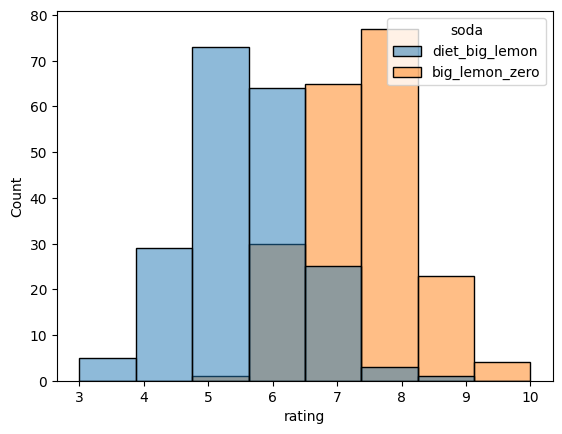

In [11]:
sb.histplot(data=soda_results, x="rating", hue="soda", bins=8);
#this will give you a histogram of the ratings for each soda, with different colors for each soda.
#The grey bars represent the distribution of ratings for all sodas combined


This tells us the "peak" of the distributions is different, with Diet BIG Lemon's average seemingly lower.

Let's verify this.

In [12]:
soda_results.groupby("soda")["rating"].mean()

soda
big_lemon_zero    7.515
diet_big_lemon    5.440
Name: rating, dtype: float64

The average rating for Diet BIG Lemon does indeed seem lower.



***Now it's time to test this statistically.***



First of all, what are our hypotheses?

The null hypothesis is that **there is no difference** between the sodas.

$$
H_0: \mu_1 = \mu_2
$$

The alternate hypothesis is that **there *is* a difference** between the sodas.

$$
H_A: \mu_1 \ne \mu_2
$$

Now we need a statistical test for this scenario.

We'll use a two-sample t-test, which specifically tests **whether there is a significant difference between two sample means**.

In this case, it helps us answer: **do the ratings of these two sodas differ significantly?**

In [13]:
from scipy import stats

In [14]:
# first, split the samples
diet_big_lemon = soda_results.loc[soda_results["soda"] == "diet_big_lemon", "rating"]
big_lemon_zero = soda_results.loc[soda_results["soda"] == "big_lemon_zero", "rating"]

# run a t-test to compare groups
# What a t-test does is it compares the means of two groups and tells you if they are 
# statistically different from each other. The null hypothesis is that the two groups 
# have the same mean, and the alternative hypothesis is that they have different means.
t_stat, p_value = stats.ttest_ind(diet_big_lemon, big_lemon_zero)

To interpret the results, we use the p-value, which tells us **how likely we are to see this data assuming our null hypothesis is true**.

That is: how likely are we to see these ratings if the sodas are equally good?

If the p-value is low enough, we can **reject the null hypothesis** and say that the two sodas are not equal.

In [15]:
print(f"T-statistic: {t_stat}")
# The t-statistic is a measure of the difference between the two group
# means relative to the variability in the groups. A larger absolute 
# value of the t-statistic indicates a greater difference between the groups.
# in this case, the value of -20.6 indicates that the mean rating for diet_big_lemon 
# is significantly lower than the mean rating for big_lemon_zero, so we can reject the 
# null hypothesis that the two groups have the same mean.

print(f"p-value: {p_value}")
# The p-value is the probability of observing a test statistic as extreme as, 
# or more extreme than, the one observed, assuming that the null hypothesis is true. 
# A smaller p-value indicates stronger evidence against the null hypothesis. In this case,
# the p-value of 9.104493313710051e-65 is extremely small, which means that there is a very 
# low probability of observing such a large difference, indicating that we can reject the null 
# hypothesis and conclude that there is a statistically significant difference between the 
# mean ratings of diet_big_lemon and big_lemon_zero.

T-statistic: -20.614866495370993
p-value: 9.104493313710051e-65


That is a tiny p-value, less that the typical threshold of 0.05.

This means **we reject the null hypothesis** and say that there **is** a difference between the sodas and that this difference is statistically significant.

# Now You Try!

We received some more test results, which we want to evaluate.

1. Read in `sodas_2.csv` as a `pandas DataFrame`.

In [16]:
sodas_2 = pd.read_csv("https://raw.githubusercontent.com/CharleyHananiaGA/DSB-Unit-02/refs/heads/main/data/sodas_2.csv")

2. What is the distribution of sodas?

In [17]:
sodas_2["soda"].value_counts()

soda
diet_big_lemon    200
big_lemon_zero    200
Name: count, dtype: int64

3. What is the distribution of ratings? Calculate this for the entire dataset, and also for each soda separately.

In [18]:
sodas_2.describe()

,rating
count,400.000000
mean,6.492500
std,1.078356
min,3.000000
25%,6.000000
50%,6.000000
75%,7.000000
max,10.000000


In [19]:
sodas_2.groupby("soda")["rating"].mean()

soda
big_lemon_zero    6.475
diet_big_lemon    6.510
Name: rating, dtype: float64

Looks like the mean ratings for each soda are very close.

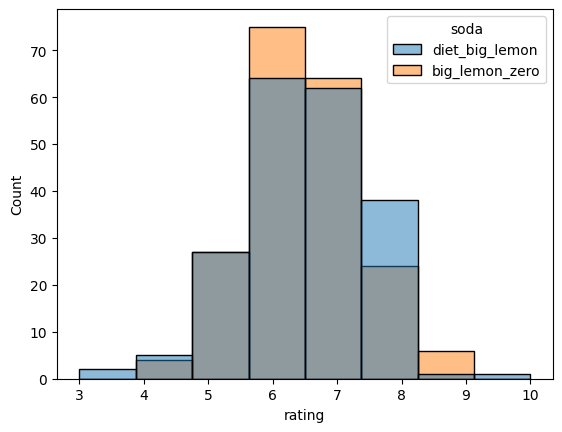

In [20]:
sb.histplot(data=sodas_2, x="rating", hue="soda", bins=8);

4. Run a two-sample t-test to see whether the sodas have similar ratings.

In [21]:
# first, split the samples
diet_big_lemon = sodas_2.loc[sodas_2["soda"] == "diet_big_lemon", "rating"]
big_lemon_zero = sodas_2.loc[sodas_2["soda"] == "big_lemon_zero", "rating"]

# run a t-test to compare groups
t_stat, p_value = stats.ttest_ind(diet_big_lemon, big_lemon_zero)

print(f"T-statistic: {t_stat}")
# The T-statistic of 0.3242040674809033 again indicates that the difference between the 
# means of the two groups is small relative to the variability within the groups. 
# This suggests that there is not a significant difference between the two groups.
# a significant difference in this case would have been indicated by a T-statistic with
# an absolute value greater than 2, which is not the case here.

print(f"p-value: {p_value}")
# The p-value of 0.746 is much larger than the commonly used significance level of 0.05,
# which means that we fail to reject the null hypothesis. In other words, there is not
# enough evidence to suggest that there is a significant difference between the mean ratings
# of diet_big_lemon and big_lemon_zero in this case.

T-statistic: 0.3242040674809033
p-value: 0.7459538558547595


The p-value is very high, around 0.75.

This means these results are very likely if the two sodas are similar.

We therefore **fail to reject the null hypothesis**.

# Conclusions and Takeaways

- Hypothesis tests require an experiment, data, and a statistical test
- If the p-value is below a certain threshold, usually 0.05, we *reject* the null hypothesis
- If the p-value is above this threshold, we *fail to reject* the null hypothesis